# Simulation of Decisional-Sensory Bias Distinction
**List of contents:**\
1- TOJ\
2- SJ\
3- Summary of Both

QUANTITATIVE COMPUTATIONAL SIMULATION FOR PSYCHOPHYSICAL PARADIGMS\
PURPOSE: Investigating Parameter Identifiability Deadlocks within the DDM Framework\
This section hosts the full simulation pipeline for both Temporal Order Judgment (TOJ) and Synchrony Judgment (SJ) tasks. It maps the latent mathematical interactions between top-down decisional boundary proximities (x0) and sensory evidence accumulation rates (v).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import fsolve
from scipy.interpolate import make_interp_spline
import matplotlib.colors as mcolors
from scipy.optimize import root_scalar
import os

In [16]:
# accuracy distribution of DDM
def acc(x0, v, a):
    return (1-np.exp(-2*x0*v))/(1-np.exp(-2*a*v))

In [17]:
# RT distribution of DDM
def hitting_time_density(t, a, x0, v):
    drift_term = np.exp((v*(a - x0)) - (v**2 * t)/2)
    if t <= 0.1:
        sum_val = 0
        for k in range(-5, 6):
            term = (a - x0 + 2 * k * a) * np.exp(-((a - x0 + 2 * k * a)**2) / (2  * t))
            sum_val += term
        pdf = (1 / np.sqrt(2 * np.pi * t**3)) * drift_term * sum_val
    
    else:
        sum_val = 0
        for k in range(1, 51):
            term = k * np.sin(k * np.pi * (a - x0) / a) * np.exp(-(k**2 * np.pi**2 * t) / (2 * a**2))
            sum_val += term
        pdf = (np.pi  / a**2) * drift_term * sum_val
        
    return max(0, pdf) 

In [18]:
# function used to find the DDM parameters which makes the matching accuracy with the SDT
def func(v, x0, a, y):
    return acc(x0, v, a) - y

In [19]:
# colormap
cnorm = mcolors.Normalize(vmin=0, vmax=100)
cmap = plt.get_cmap('coolwarm')

# 1- TOJ

In [20]:
# approximate group SDT parameter values
c = -40
sd = 255

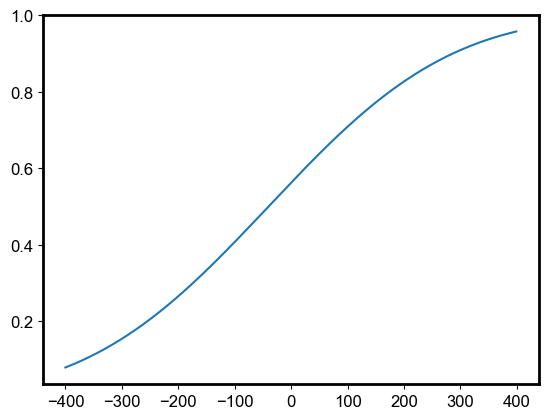

In [21]:
# probability of 'visual-first' choice
plt.plot(np.arange(-400,400,1), norm.cdf(np.arange(-400,400,1), loc=c, scale=sd))
plt.show()

In [13]:
a = 1
Drift = []
Up_mrt = []
Down_mrt = []
Up_sdrt = []
Down_sdrt = []
r = [-400, -200, -100, -50, 0, 50, 100, 200, 400]
for x0 in np.arange(.3,.75,.05):
    drift = []
    up_mrt = []
    down_mrt = []
    up_sdrt = []
    down_sdrt = []
    for soa in r:
        v = fsolve(func, 0.01, args=(x0, a, norm.cdf(soa, loc=c, scale=sd)))
        drift.append(v)
        up = []
        down = []
        for t in np.arange(0,5,.001):
            up.append(hitting_time_density(t, a, x0, v[0]))
            down.append(hitting_time_density(t, a, a-x0, -v[0]))
        up = np.array(up)
        down = np.array(down)
        up_mrt.append(np.sum(up*np.arange(0,5,.001))*.001/(np.sum(up)*.001))
        down_mrt.append(np.sum(down*np.arange(0,5,.001))*.001/(np.sum(down)*.001))
        up_sdrt.append(np.sqrt(np.sum(up*np.arange(0,5,.001)**2)*.001/(np.sum(up)*.001) - (np.sum(up*np.arange(0,5,.001))*.001/(np.sum(up)*.001))**2))
        down_sdrt.append(np.sqrt(np.sum(down*np.arange(0,5,.001)**2)*.001/(np.sum(down)*.001) - (np.sum(down*np.arange(0,5,.001))*.001/(np.sum(down)*.001))**2))
    Drift.append(drift)
    Up_mrt.append(up_mrt)
    Down_mrt.append(down_mrt)
    Up_sdrt.append(up_sdrt)
    Down_sdrt.append(down_sdrt)

C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\1960263332.py:6: RuntimeWarning: divide by zero encountered in scalar divide
  term = (a - x0 + 2 * k * a) * np.exp(-((a - x0 + 2 * k * a)**2) / (2  * t))
C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\1960263332.py:8: RuntimeWarning: divide by zero encountered in scalar divide
  pdf = (1 / np.sqrt(2 * np.pi * t**3)) * drift_term * sum_val
C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\1960263332.py:8: RuntimeWarning: invalid value encountered in scalar multiply
  pdf = (1 / np.sqrt(2 * np.pi * t**3)) * drift_term * sum_val


SIMULATION ARCHITECTURE (3x2 Subplot Layout):
- Panel A: Simulated non-linear Drift Rate Functions (v) across the SOA continuum.
- Panel B: Mean Reaction Times (RT) for upper-boundary hits ('Visual-Lead' choices).
- Panel C: Mean Reaction Times (RT) for lower-boundary hits ('Auditory-Lead' choices).
- Panel D: Parametric mapping of Decisional Bias (x0) vs. Induced Sensory Bias (Brentq Roots).
- Panel E: Standard Deviation of Reaction Times (SD_RT) for upper-boundary hits.
- Panel F: Standard Deviation of Reaction Times (SD_RT) for lower-boundary hits.

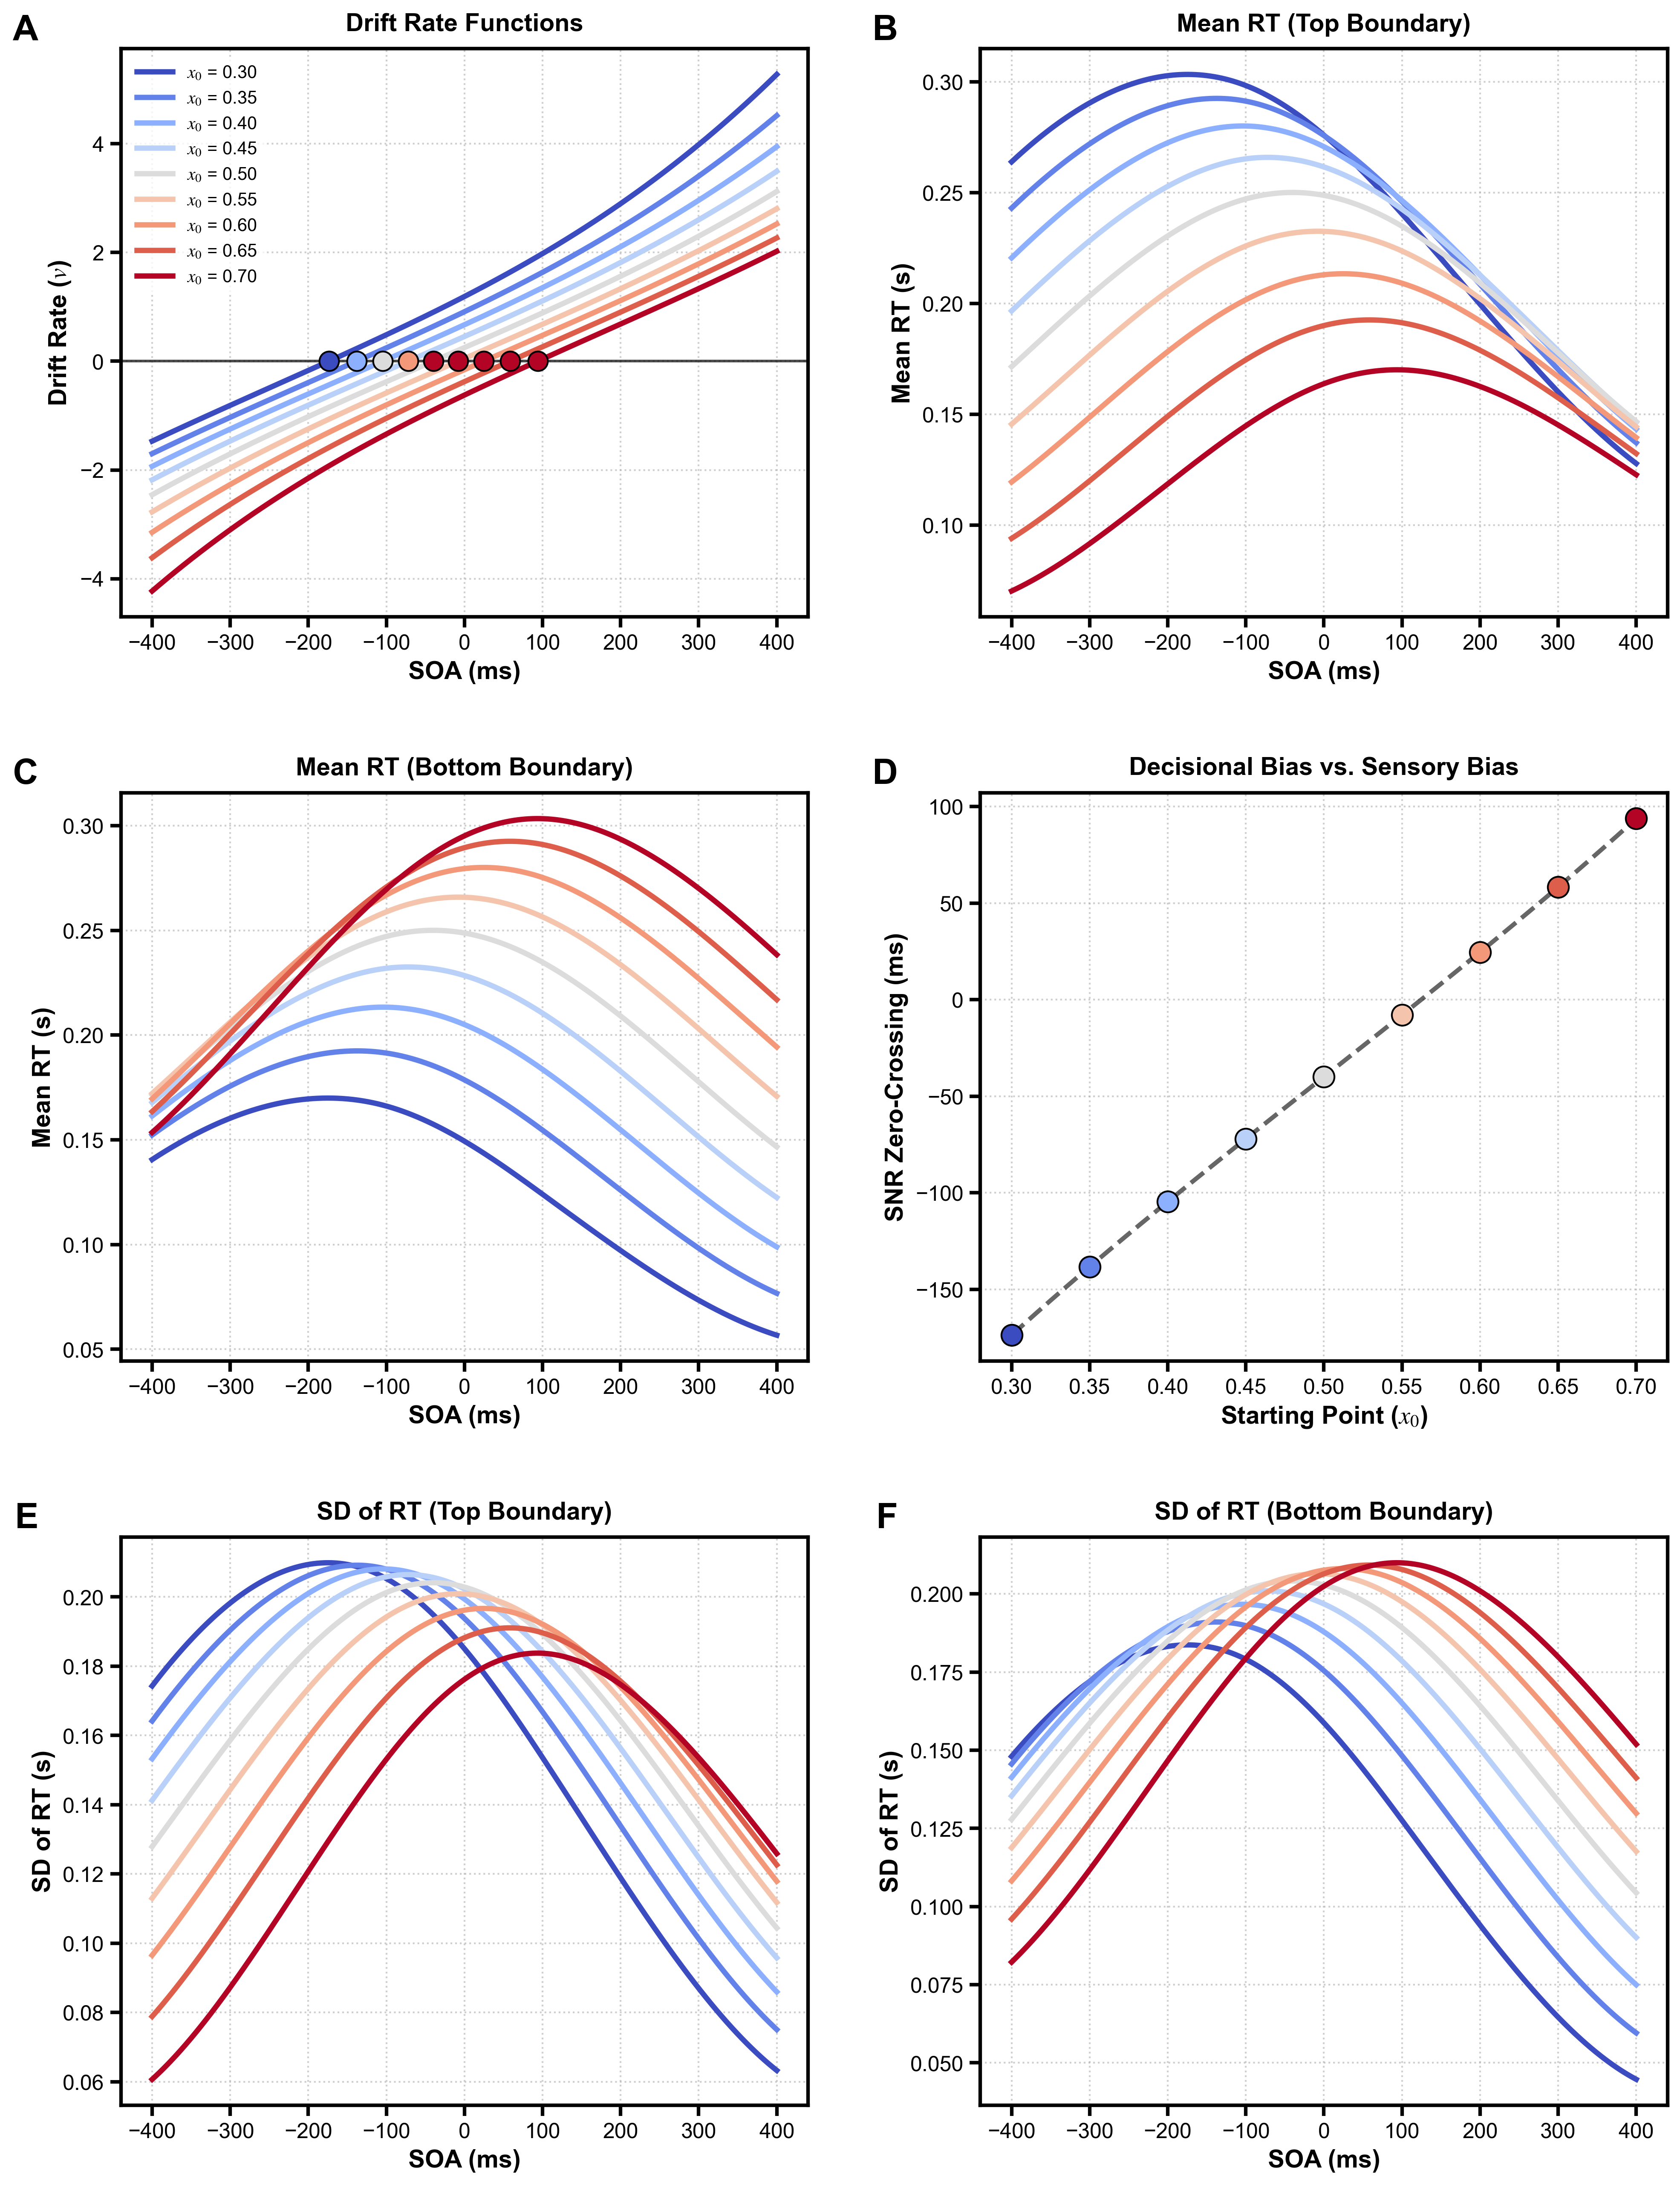

In [24]:
# =====================================================================
# 1. GRAPHICS CONFIGURATION (HIGH-RES)
# =====================================================================
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'Liberation Sans']
plt.rcParams['mathtext.fontset'] = 'stix'

# Increase font sizes and thicken frame lines for enhanced readability
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['axes.linewidth'] = 2.0  # Thicker plot borders

# Initialize a 3x2 subplot grid (3 Rows, 2 Columns) with vertical optimization
fig, axes = plt.subplots(3, 2, figsize=(14, 18), dpi=300)
axes = axes.flatten()  # Flatten to 1D array for elegant 0-5 indexing

# Add prominent bold labels (A to F) to the top-left of each subplot panel
letters = ['A', 'B', 'C', 'D', 'E', 'F']
for idx, ax in enumerate(axes):
    ax.text(-0.12, 1.06, letters[idx], transform=ax.transAxes,
            fontsize=20, fontweight='bold', va='top', ha='right')
    ax.tick_params(direction='out', length=6, width=2)  # Pronounced tick marks
    ax.grid(True, linestyle=':', alpha=0.6, linewidth=1)  # Structural background grid

sol = np.zeros(9)
x0_arr = np.arange(.3, .75, .05)

# =====================================================================
# 2. COMPUTATIONAL MODEL ITERATION & LINEWIDTH PROFILE ENHANCEMENT
# =====================================================================
for i in range(9):
    x_smooth = np.linspace(-400, 400, 500)
    current_label = f'$x_0$ = {x0_arr[i]:.2f}'
    current_color = cmap(cnorm(i*100/8))
    
    # Panel A (Index 0): Drift Rate Functions
    spline = make_interp_spline(r, Drift[i], k=3)
    y_smooth = spline(x_smooth)
    axes[0].plot(x_smooth, y_smooth, label=current_label, c=current_color, linewidth=3.0)
    
    # Numerically isolate the roots (zero-crossings) and plot as distinct bold markers
    sol[i] = root_scalar(spline, bracket=[-400, 400], method='brentq').root
    axes[0].scatter(sol[i], 0, color=cmap(cnorm(i*100/4)), s=120, zorder=5, edgecolor='k', linewidth=1)
    
    # Panel B (Index 1): Mean Reaction Times (Top Boundary)
    spline_up = make_interp_spline(r, Up_mrt[i], k=3)
    axes[1].plot(x_smooth, spline_up(x_smooth), c=current_color, linewidth=3.0)
    
    # Panel C (Index 2): Mean Reaction Times (Bottom Boundary)
    spline_down = make_interp_spline(r, Down_mrt[i], k=3)
    axes[2].plot(x_smooth, spline_down(x_smooth), c=current_color, linewidth=3.0)
    
    # Panel E (Index 4): Standard Deviation of RT (Top Boundary)
    spline_up_sd = make_interp_spline(r, Up_sdrt[i], k=3)
    axes[4].plot(x_smooth, spline_up_sd(x_smooth), c=current_color, linewidth=3.0)
    
    # Panel F (Index 5): Standard Deviation of RT (Bottom Boundary)
    spline_down_sd = make_interp_spline(r, Down_sdrt[i], k=3)
    axes[5].plot(x_smooth, spline_down_sd(x_smooth), c=current_color, linewidth=3.0)
    
    # Panel D (Index 3): Decisional Bias vs. Sensory Bias Scatter Space
    axes[3].scatter(x0_arr[i], sol[i], color=current_color, s=140, zorder=5, edgecolor='k', linewidth=1)

# Superimpose the zero baseline on the drift rate function coordinate system
axes[0].axhline(0, color='black', linestyle='-', linewidth=1.5, alpha=0.7)

# Fit a smooth spline tracking the relationship between starting point and zero-crossings in Panel D
x_smooth_sol = np.linspace(.3, .7, 500)
spline_sol = make_interp_spline(x0_arr, sol, k=3)
axes[3].plot(x_smooth_sol, spline_sol(x_smooth_sol), c='black', alpha=0.6, linestyle='--', linewidth=2.5)

# =====================================================================
# 3. TEXTUAL LABELS & SCIENTIFIC ANNOTATION ARCHITECTURE (BOLD)
# =====================================================================
axes[0].set_title('Drift Rate Functions', fontweight='bold', pad=10)
axes[0].set_xlabel('SOA (ms)', fontweight='bold')
axes[0].set_ylabel('Drift Rate ($v$)', fontweight='bold')

axes[1].set_title('Mean RT (Top Boundary)', fontweight='bold', pad=10)
axes[1].set_xlabel('SOA (ms)', fontweight='bold')
axes[1].set_ylabel('Mean RT (s)', fontweight='bold')

axes[2].set_title('Mean RT (Bottom Boundary)', fontweight='bold', pad=10)
axes[2].set_xlabel('SOA (ms)', fontweight='bold')
axes[2].set_ylabel('Mean RT (s)', fontweight='bold')

axes[3].set_title('Decisional Bias vs. Sensory Bias', fontweight='bold', pad=10)
axes[3].set_xlabel('Starting Point ($x_0$)', fontweight='bold')
axes[3].set_ylabel('SNR Zero-Crossing (ms)', fontweight='bold')

axes[4].set_title('SD of RT (Top Boundary)', fontweight='bold', pad=10)
axes[4].set_xlabel('SOA (ms)', fontweight='bold')
axes[4].set_ylabel('SD of RT (s)', fontweight='bold')

axes[5].set_title('SD of RT (Bottom Boundary)', fontweight='bold', pad=10)
axes[5].set_xlabel('SOA (ms)', fontweight='bold')
axes[5].set_ylabel('SD of RT (s)', fontweight='bold')

# Display a single integrated legend box on Panel A to preserve layout cleanliness
axes[0].legend(loc='best', frameon=True, facecolor='white', edgecolor='none', framealpha=0.8)

plt.tight_layout(pad=4.0)  # Enhanced spacing for 3x2 architecture

# =====================================================================
# 4. DIRECTORY VERIFICATION & ULTRA HIGH-RES VECTOR EXPORT ROUTINE
# =====================================================================
save_directory = r"figures"
pdf_path = os.path.join(save_directory, "TOJ_Simulation_3x2_HighRes.pdf")
plt.savefig(pdf_path, format="pdf", dpi=600, bbox_inches="tight")
plt.show()

# 2- SJ

In [26]:
# approximate group SDT parameter values
c_low = -255
c_high = 195
sd = 107

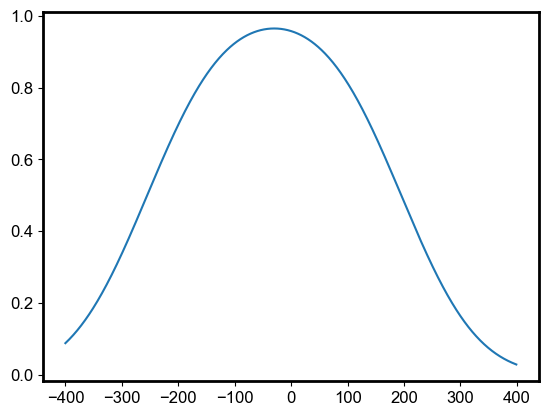

In [27]:
# probability of 'synchrony' choice
plt.plot(np.arange(-400,400,1), norm.cdf(np.arange(-400,400,1), loc=c_low, scale=sd) - norm.cdf(np.arange(-400,400,1), loc=c_high, scale=sd))
plt.show()

In [28]:
a = 1
Drift = []
Up_mrt = []
Down_mrt = []
Up_sdrt = []
Down_sdrt = []
for x0 in np.arange(.3,.75,.05):
    drift = []
    up_mrt = []
    down_mrt = []
    up_sdrt = []
    down_sdrt = []
    r = np.arange(-400,401,50)
    for soa in r:
        v = fsolve(func, 0.01, args=(x0, a, norm.cdf(soa, loc=c_low, scale=sd) - norm.cdf(soa, loc=c_high, scale=sd)))
        drift.append(v)
        up = []
        down = []
        for t in np.arange(0,5,.001):
            up.append(hitting_time_density(t, a, x0, v[0]))
            down.append(hitting_time_density(t, a, a-x0, -v[0]))
        up = np.array(up)
        down = np.array(down)
        up_mrt.append(np.sum(up*np.arange(0,5,.001))*.001/(np.sum(up)*.001))
        down_mrt.append(np.sum(down*np.arange(0,5,.001))*.001/(np.sum(down)*.001))
        up_sdrt.append(np.sqrt(np.sum(up*np.arange(0,5,.001)**2)*.001/(np.sum(up)*.001) - (np.sum(up*np.arange(0,5,.001))*.001/(np.sum(up)*.001))**2))
        down_sdrt.append(np.sqrt(np.sum(down*np.arange(0,5,.001)**2)*.001/(np.sum(down)*.001) - (np.sum(down*np.arange(0,5,.001))*.001/(np.sum(down)*.001))**2))
    Drift.append(drift)
    Up_mrt.append(up_mrt)
    Down_mrt.append(down_mrt)
    Up_sdrt.append(up_sdrt)
    Down_sdrt.append(down_sdrt)

C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\3464842012.py:7: RuntimeWarning: divide by zero encountered in scalar divide
  term = (a - x0 + 2 * k * a) * np.exp(-((a - x0 + 2 * k * a)**2) / (2  * t))
C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\3464842012.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  pdf = (1 / np.sqrt(2 * np.pi * t**3)) * drift_term * sum_val
C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\3464842012.py:9: RuntimeWarning: invalid value encountered in scalar multiply
  pdf = (1 / np.sqrt(2 * np.pi * t**3)) * drift_term * sum_val


SIMULATION ARCHITECTURE (3x2 Subplot Layout):
- Panel A: Non-monotonic, concave Drift Rate Functions (v) across the SOA continuum.
- Panel B: Mean Reaction Times (RT) for upper-boundary hits ('Synchrony' choices).
- Panel C: Mean Reaction Times (RT) for lower-boundary hits ('Asynchrony' choices).
- Panel D: Parametric mapping of Decisional Bias (x0) vs. Dual Synchrony Bound Alignments.
- Panel E: Standard Deviation of Reaction Times (SD_RT) for synchrony classification responses.
- Panel F: Standard Deviation of Reaction Times (SD_RT) for asynchrony classification responses.

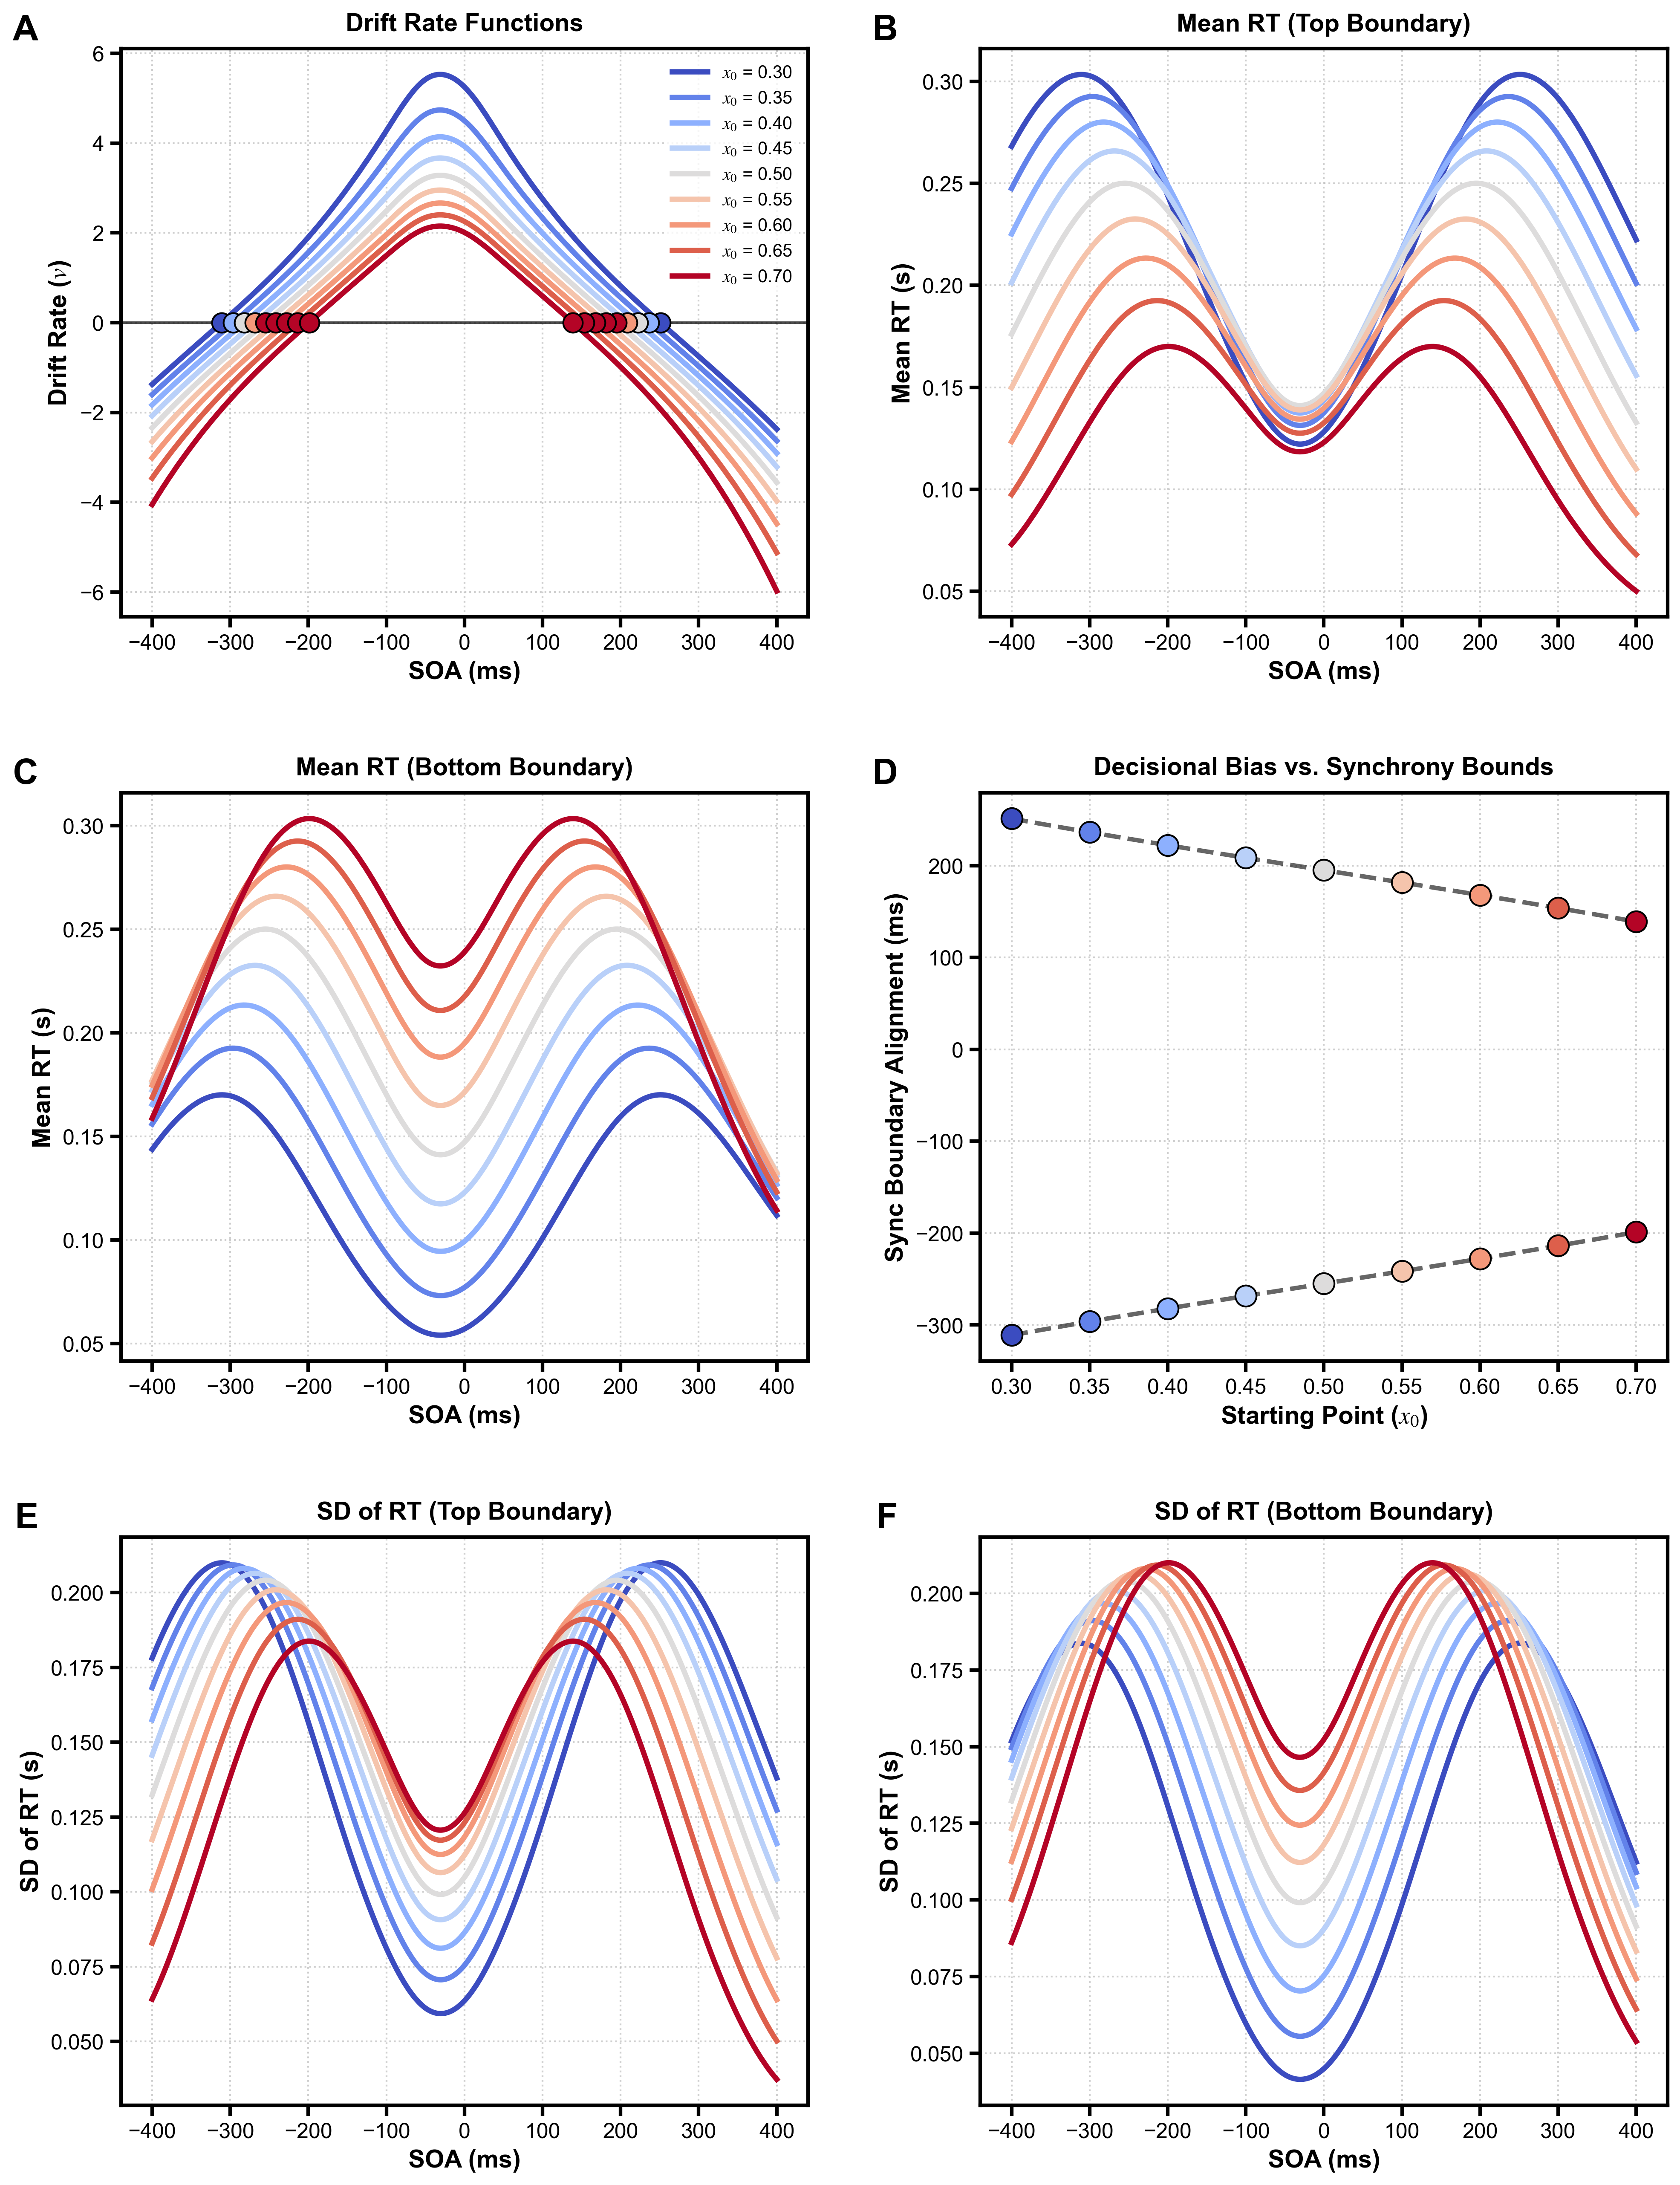

In [29]:
# =====================================================================
# 1. GRAPHICS CONFIGURATION FOR ELIFE & NATURE STANDARDS (HIGH-RES)
# =====================================================================
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'Liberation Sans']
plt.rcParams['mathtext.fontset'] = 'stix'

# Increase font sizes and thicken frame lines for enhanced readability
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['axes.linewidth'] = 2.0  # Thicker plot borders

# Initialize a 3x2 subplot grid (3 Rows, 2 Columns) with vertical optimization
fig, axes = plt.subplots(3, 2, figsize=(14, 18), dpi=300)
axes = axes.flatten()  # Flatten to 1D array for elegant 0-5 indexing

# Add prominent bold labels (A to F) to the top-left of each subplot panel
letters = ['A', 'B', 'C', 'D', 'E', 'F']
for idx, ax in enumerate(axes):
    ax.text(-0.12, 1.06, letters[idx], transform=ax.transAxes,
            fontsize=20, fontweight='bold', va='top', ha='right')
    ax.tick_params(direction='out', length=6, width=2)  # Pronounced tick marks
    ax.grid(True, linestyle=':', alpha=0.6, linewidth=1)  # Structural background grid

# Note: SJ task requires tracking two roots (lower and upper boundaries)
sol = np.zeros((9, 2))
x0_arr = np.arange(.3, .75, .05)

# =====================================================================
# 2. COMPUTATIONAL MODEL ITERATION & LINEWIDTH PROFILE ENHANCEMENT
# =====================================================================
for i in range(9):
    x_smooth = np.linspace(-400, 400, 500)
    current_label = f'$x_0$ = {x0_arr[i]:.2f}'
    current_color = cmap(cnorm(i*100/8))
    
    # Panel A (Index 0): Drift Rate Functions
    spline = make_interp_spline(r, Drift[i], k=3)
    y_smooth = spline(x_smooth)
    axes[0].plot(x_smooth, y_smooth, label=current_label, c=current_color, linewidth=3.0)
    
    # Numerically isolate both roots (negative and positive bounds) for the SJ window
    sol[i, 0] = root_scalar(spline, bracket=[-400, 0], method='brentq').root
    sol[i, 1] = root_scalar(spline, bracket=[0, 400], method='brentq').root
    
    # Plot both detected zero-crossing points as bold markers
    axes[0].scatter([sol[i, 0], sol[i, 1]], [0, 0], color=cmap(cnorm(i*100/4)), s=120, zorder=5, edgecolor='k', linewidth=1)
    
    # Panel B (Index 1): Mean Reaction Times (Top Boundary)
    spline_up = make_interp_spline(r, Up_mrt[i], k=3)
    axes[1].plot(x_smooth, spline_up(x_smooth), c=current_color, linewidth=3.0)
    
    # Panel C (Index 2): Mean Reaction Times (Bottom Boundary)
    spline_down = make_interp_spline(r, Down_mrt[i], k=3)
    axes[2].plot(x_smooth, spline_down(x_smooth), c=current_color, linewidth=3.0)
    
    # Panel E (Index 4): Standard Deviation of RT (Top Boundary)
    spline_up_sd = make_interp_spline(r, Up_sdrt[i], k=3)
    axes[4].plot(x_smooth, spline_up_sd(x_smooth), c=current_color, linewidth=3.0)
    
    # Panel F (Index 5): Standard Deviation of RT (Bottom Boundary)
    spline_down_sd = make_interp_spline(r, Down_sdrt[i], k=3)
    axes[5].plot(x_smooth, spline_down_sd(x_smooth), c=current_color, linewidth=3.0)
    
    # Panel D (Index 3): Decisional Bias vs. Synchrony Bounds Scatter Space (Both Bounds)
    axes[3].scatter(x0_arr[i], sol[i, 0], color=current_color, s=140, zorder=5, edgecolor='k', linewidth=1)
    axes[3].scatter(x0_arr[i], sol[i, 1], color=current_color, s=140, zorder=5, edgecolor='k', linewidth=1)

# Superimpose the zero baseline on the drift rate function coordinate system
axes[0].axhline(0, color='black', linestyle='-', linewidth=1.5, alpha=0.7)

# Fit smooth splines tracking the dual-boundary sync profiles in Panel D
x_smooth_sol = np.linspace(.3, .7, 500)
spline_sol_lower = make_interp_spline(x0_arr, sol[:, 0], k=3)
spline_sol_upper = make_interp_spline(x0_arr, sol[:, 1], k=3)

axes[3].plot(x_smooth_sol, spline_sol_lower(x_smooth_sol), c='black', alpha=0.6, linestyle='--', linewidth=2.5)
axes[3].plot(x_smooth_sol, spline_sol_upper(x_smooth_sol), c='black', alpha=0.6, linestyle='--', linewidth=2.5)

# =====================================================================
# 3. TEXTUAL LABELS & SCIENTIFIC ANNOTATION ARCHITECTURE (BOLD)
# =====================================================================
axes[0].set_title('Drift Rate Functions', fontweight='bold', pad=10)
axes[0].set_xlabel('SOA (ms)', fontweight='bold')
axes[0].set_ylabel('Drift Rate ($v$)', fontweight='bold')

axes[1].set_title('Mean RT (Top Boundary)', fontweight='bold', pad=10)
axes[1].set_xlabel('SOA (ms)', fontweight='bold')
axes[1].set_ylabel('Mean RT (s)', fontweight='bold')

axes[2].set_title('Mean RT (Bottom Boundary)', fontweight='bold', pad=10)
axes[2].set_xlabel('SOA (ms)', fontweight='bold')
axes[2].set_ylabel('Mean RT (s)', fontweight='bold')

axes[3].set_title('Decisional Bias vs. Synchrony Bounds', fontweight='bold', pad=10)
axes[3].set_xlabel('Starting Point ($x_0$)', fontweight='bold')
axes[3].set_ylabel('Sync Boundary Alignment (ms)', fontweight='bold')

axes[4].set_title('SD of RT (Top Boundary)', fontweight='bold', pad=10)
axes[4].set_xlabel('SOA (ms)', fontweight='bold')
axes[4].set_ylabel('SD of RT (s)', fontweight='bold')

axes[5].set_title('SD of RT (Bottom Boundary)', fontweight='bold', pad=10)
axes[5].set_xlabel('SOA (ms)', fontweight='bold')
axes[5].set_ylabel('SD of RT (s)', fontweight='bold')

# Display a single integrated legend box on Panel A to preserve layout cleanliness
axes[0].legend(loc='best', frameon=True, facecolor='white', edgecolor='none', framealpha=0.8)

plt.tight_layout(pad=4.0)  # Enhanced spacing for 3x2 architecture

# =====================================================================
# 4. DIRECTORY VERIFICATION & ULTRA HIGH-RES VECTOR EXPORT ROUTINE
# =====================================================================
save_directory = r"figures"
pdf_path = os.path.join(save_directory, "SJ_Simulation_3x2_HighRes.pdf")
plt.savefig(pdf_path, format="pdf", dpi=600, bbox_inches="tight")
plt.show()

# 3- Summary of Both

HIGH-RESOLUTION MULTI-PANEL RENDERING FOR MAIN TEXT \
Architectural Design:
- Condenses full simulation parameters into a unified 2x2 publication-grade layout.
- Row 1 (Panels A & B): TOJ drift trajectories and upper-boundary Mean RT profiles.
- Row 2 (Panels C & D): SJ drift trajectories and upper-boundary Mean RT profiles.

In [30]:
x0_range = np.arange(0.3, 0.75, 0.05)
t_steps = np.arange(0, 5, 0.001)

In [31]:
# =====================================================================
#  TOJ Simulation Block
# =====================================================================
c_TOJ = -40
sd_TOJ = 255
a = 1

r_TOJ = [-400, -200, -100, -50, 0, 50, 100, 200, 400]
Drift_TOJ = []
Up_mrt_TOJ = []

for x0 in x0_range:
    drift = []
    up_mrt = []
    for soa in r_TOJ:
        v = fsolve(func, 0.01, args=(x0, a, norm.cdf(soa, loc=c_TOJ, scale=sd_TOJ)))
        drift.append(v[0])

        up = np.array(
            [hitting_time_density(t, a, x0, v[0]) for t in t_steps]
        )
        up_mrt.append(np.sum(up * t_steps) * 0.001 / (np.sum(up) * 0.001))
    Drift_TOJ.append(drift)
    Up_mrt_TOJ.append(up_mrt)

C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\3464842012.py:7: RuntimeWarning: divide by zero encountered in scalar divide
  term = (a - x0 + 2 * k * a) * np.exp(-((a - x0 + 2 * k * a)**2) / (2  * t))
C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\3464842012.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  pdf = (1 / np.sqrt(2 * np.pi * t**3)) * drift_term * sum_val
C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\3464842012.py:9: RuntimeWarning: invalid value encountered in scalar multiply
  pdf = (1 / np.sqrt(2 * np.pi * t**3)) * drift_term * sum_val


In [33]:
# =====================================================================
#  SJ Simulation Block
# =====================================================================
c_low_SJ = -255
c_high_SJ = 195
sd_SJ = 107

r_SJ = np.arange(-400, 401, 50)
Drift_SJ = []
Up_mrt_SJ = []

for x0 in x0_range:
    drift = []
    up_mrt = []
    for soa in r_SJ:
        y_val = norm.cdf(soa, loc=c_low_SJ, scale=sd_SJ) - norm.cdf(
            soa, loc=c_high_SJ, scale=sd_SJ
        )
        v = fsolve(func, 0.01, args=(x0, a, y_val))
        drift.append(v[0])

        up = np.array(
            [hitting_time_density(t, a, x0, v[0]) for t in t_steps]
        )
        up_mrt.append(np.sum(up * t_steps) * 0.001 / (np.sum(up) * 0.001))
    Drift_SJ.append(drift)
    Up_mrt_SJ.append(up_mrt)

C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\3464842012.py:7: RuntimeWarning: divide by zero encountered in scalar divide
  term = (a - x0 + 2 * k * a) * np.exp(-((a - x0 + 2 * k * a)**2) / (2  * t))
C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\3464842012.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  pdf = (1 / np.sqrt(2 * np.pi * t**3)) * drift_term * sum_val
C:\Users\Hasan\AppData\Local\Temp\ipykernel_6736\3464842012.py:9: RuntimeWarning: invalid value encountered in scalar multiply
  pdf = (1 / np.sqrt(2 * np.pi * t**3)) * drift_term * sum_val


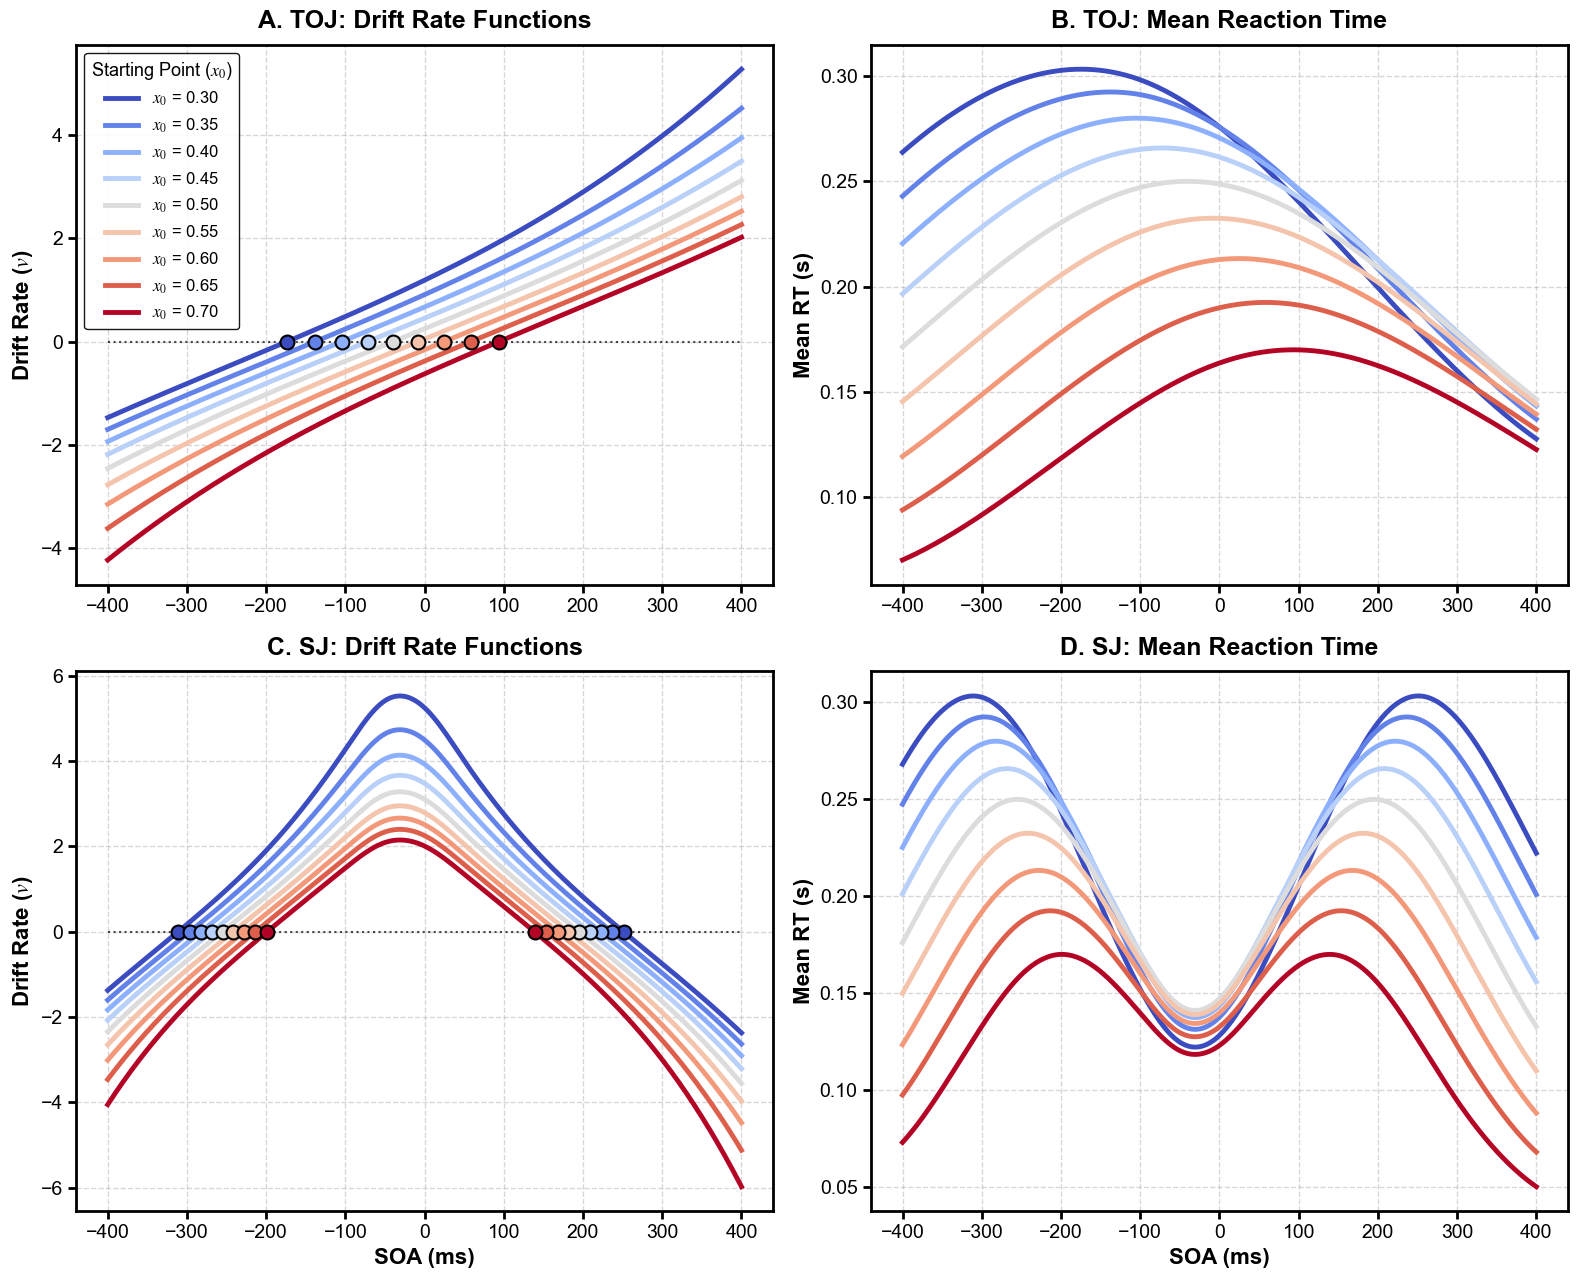

In [34]:
# Global RC Parameters for Publication-Quality Aesthetics
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 14                  # Increased baseline font size
plt.rcParams["axes.linewidth"] = 2.0            # Made frame borders much thicker

# Expanded figure size to give space for bold elements
fig, ax = plt.subplots(2, 2, figsize=(16, 13))
x_smooth = np.linspace(-400, 400, 500)

for i in range(len(x0_range)):
    color_val = cmap(cnorm(i * 100 / (len(x0_range) - 1)))

    # ------------------ Row 1: TOJ Task ------------------
    # Panel A: TOJ Drift Rate (Added labels for the prominent Legend)
    spline_v_toj = make_interp_spline(r_TOJ, Drift_TOJ[i], k=3)
    ax[0, 0].plot(
        x_smooth,
        spline_v_toj(x_smooth),
        c=color_val,
        linewidth=3.5,                           # Thicker lines for visual clarity
        label=f"$x_0$ = {x0_range[i]:.2f}",
    )
    
    # root finding for TOJ drift
    try:
        sol_toj = root_scalar(spline_v_toj, bracket=[-400, 400], method='brentq')
        if sol_toj.converged:
            ax[0, 0].plot(sol_toj.root, 0, marker='o', markersize=10, 
                          markerfacecolor=color_val, markeredgecolor='black', markeredgewidth=1.5, zorder=5)
    except ValueError:
        pass

    # Panel B: TOJ Mean RT
    spline_rt_toj = make_interp_spline(r_TOJ, Up_mrt_TOJ[i], k=3)
    ax[0, 1].plot(x_smooth, spline_rt_toj(x_smooth), c=color_val, linewidth=3.5)

    # ------------------ Row 2: SJ Task ------------------
    # Panel C: SJ Drift Rate
    spline_v_sj = make_interp_spline(r_SJ, Drift_SJ[i], k=3)
    ax[1, 0].plot(x_smooth, spline_v_sj(x_smooth), c=color_val, linewidth=3.5)
    
    # root finding for SJ drift
    for bracket in [[-400, 0], [0, 400]]:
        try:
            sol_sj = root_scalar(spline_v_sj, bracket=bracket, method='brentq')
            if sol_sj.converged:
                ax[1, 0].plot(sol_sj.root, 0, marker='o', markersize=10, 
                              markerfacecolor=color_val, markeredgecolor='black', markeredgewidth=1.5, zorder=5)
        except ValueError:
            pass

    # Panel D: SJ Mean RT
    spline_rt_sj = make_interp_spline(r_SJ, Up_mrt_SJ[i], k=3)
    ax[1, 1].plot(x_smooth, spline_rt_sj(x_smooth), c=color_val, linewidth=3.5)

# --- Subplot Refinements with Large & Bold Text Components ---

# Top-Left (TOJ Drift)
ax[0, 0].plot([-400, 400], [0, 0], c="k", linestyle=":", alpha=0.7, linewidth=1.5)
ax[0, 0].set_title("A. TOJ: Drift Rate Functions", fontweight="bold", fontsize=18, pad=12)
ax[0, 0].set_ylabel("Drift Rate ($v$)", fontweight="bold", fontsize=16)
ax[0, 0].grid(True, linestyle="--", alpha=0.5, linewidth=1)
ax[0, 0].tick_params(axis='both', labelsize=14, width=2, length=6)
# High-contrast bold legend explicitly listing the colors mapping to x0 values
ax[0, 0].legend(loc="upper left", title="Starting Point ($x_0$)", fontsize=12, title_fontsize=13, framealpha=0.9, edgecolor='black')

# Top-Right (TOJ Mean RT)
ax[0, 1].set_title("B. TOJ: Mean Reaction Time", fontweight="bold", fontsize=18, pad=12)
ax[0, 1].set_ylabel("Mean RT (s)", fontweight="bold", fontsize=16)
ax[0, 1].grid(True, linestyle="--", alpha=0.5, linewidth=1)
ax[0, 1].tick_params(axis='both', labelsize=14, width=2, length=6)

# Bottom-Left (SJ Drift)
ax[1, 0].plot([-400, 400], [0, 0], c="k", linestyle=":", alpha=0.7, linewidth=1.5)
ax[1, 0].set_title("C. SJ: Drift Rate Functions", fontweight="bold", fontsize=18, pad=12)
ax[1, 0].set_xlabel("SOA (ms)", fontweight="bold", fontsize=16)
ax[1, 0].set_ylabel("Drift Rate ($v$)", fontweight="bold", fontsize=16)
ax[1, 0].grid(True, linestyle="--", alpha=0.5, linewidth=1)
ax[1, 0].tick_params(axis='both', labelsize=14, width=2, length=6)

# Bottom-Right (SJ Mean RT)
ax[1, 1].set_title("D. SJ: Mean Reaction Time", fontweight="bold", fontsize=18, pad=12)
ax[1, 1].set_xlabel("SOA (ms)", fontweight="bold", fontsize=16)
ax[1, 1].set_ylabel("Mean RT (s)", fontweight="bold", fontsize=16)
ax[1, 1].grid(True, linestyle="--", alpha=0.5, linewidth=1)
ax[1, 1].tick_params(axis='both', labelsize=14, width=2, length=6)

plt.tight_layout()

# =====================================================================
#  Directory Verification and Ultra High-Res Saving
# =====================================================================
save_directory = r"figures"
pdf_path = os.path.join(save_directory, "Figure3_Simulation_Combined.pdf")
plt.savefig(pdf_path, format="pdf", dpi=300, bbox_inches="tight")
plt.show()